In [1]:
# Import libraries and load the engineered dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Load the engineered dataset
master_df = pd.read_csv('master_engineered_sales.csv')

# Ensure 'date' column is datetime and sorted chronologically
master_df['date'] = pd.to_datetime(master_df['date'])
master_df = master_df.sort_values(by=['store_id', 'department', 'date']).reset_index(drop=True)

print("Dataset loaded successfully (Advanced ML Modeling)!")
print(f"Dataset Shape: {master_df.shape}")
display(master_df.head(3))

Dataset loaded successfully (Advanced ML Modeling)!
Dataset Shape: (152000, 26)


,store_id,department,date,weekly_sales,is_holiday,store_size,temperature,fuel_price,markdown_1,markdown_2,...,sales_lag_4,sales_rolling_mean_4,season_Spring,season_Summer,season_Winter,store_type_B,store_type_C,region_North,region_South,region_West
0,1,1,2022-01-29,15166.69,0,213810,78.37,4.41,4436.06,1416.64,...,119075.96,53675.7850,False,False,True,False,False,True,False,False
1,1,1,2022-02-05,15601.13,0,213810,59.50,4.07,2137.71,76.26,...,35525.05,27698.4675,False,False,True,False,False,True,False,False
2,1,1,2022-02-12,52743.22,0,213810,92.61,3.25,2051.91,2266.65,...,14847.56,22717.4875,False,False,True,False,False,True,False,False


In [2]:
# Prepare data, select features, and train-test split for ML Models (Store 1, Dept 1)
store_id = 1
dept_id = 1

df_sample = master_df[(master_df['store_id'] == store_id) & (master_df['department'] == dept_id)].copy()
df_sample = df_sample.sort_values('date').reset_index(drop=True)

# Define feature columns (excluding target, date, and identifiers)
exclude_cols = ['store_id', 'department', 'date', 'weekly_sales']
feature_cols = [col for col in df_sample.columns if col not in exclude_cols]

# Train-Test Split (consistent with previous notebooks: last 12 weeks for testing)
train_df = df_sample.iloc[:-12]
test_df = df_sample.iloc[-12:]

X_train = train_df[feature_cols]
y_train = train_df['weekly_sales']
X_test = test_df[feature_cols]
y_test = test_df['weekly_sales']

print(f"Features used for ML Training: {len(feature_cols)}")
print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")

Features used for ML Training: 22
X_train shape: (140, 22), X_test shape: (12, 22)


--- Machine Learning Model Performance ---
XGBoost -> MAE: 46509.10, RMSE: 52676.87, MAPE: 114.37%
Random Forest -> MAE: 45314.37, RMSE: 49028.19, MAPE: 108.30%

--- Top 5 Important Features (XGBoost) ---


,Feature,Importance
12,sales_lag_4,0.181169
0,is_holiday,0.131695
6,markdown_3,0.119387
9,cpi,0.096800
10,unemployment,0.064334


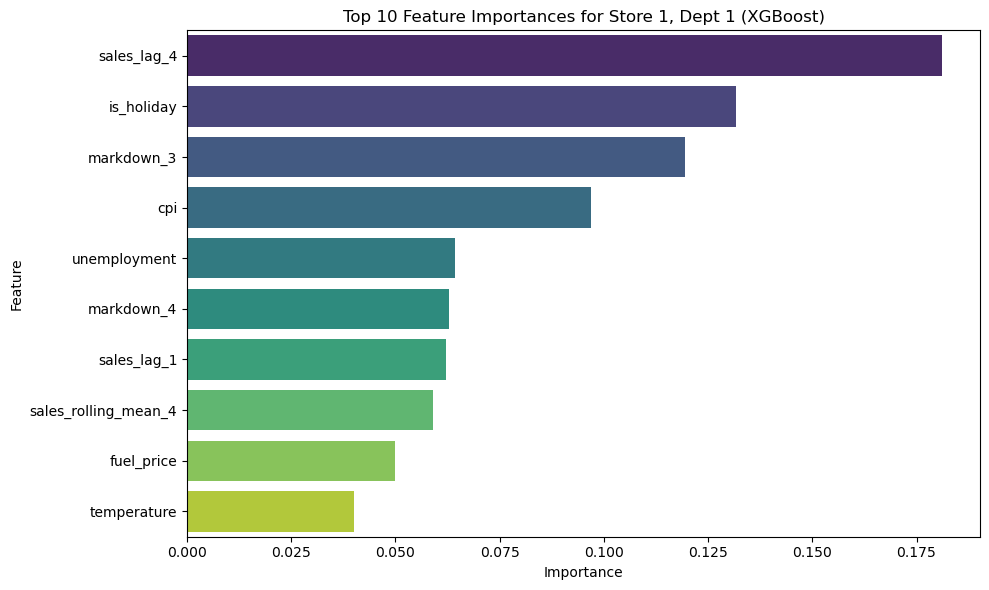

In [3]:
# Train XGBoost and Random Forest Regressors, Evaluate, and Feature Importance
from sklearn.metrics import mean_absolute_percentage_error

# 1. Train XGBoost
xgb_model = XGBRegressor(n_estimators=100, learning_rate=0.05, random_state=42)
xgb_model.fit(X_train, y_train)
xgb_preds = xgb_model.predict(X_test)

xgb_mae = mean_absolute_error(y_test, xgb_preds)
xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_preds))
xgb_mape = mean_absolute_percentage_error(y_test, xgb_preds) * 100

# 2. Train Random Forest
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
rf_preds = rf_model.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_preds)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_preds))
rf_mape = mean_absolute_percentage_error(y_test, rf_preds) * 100

print("--- Machine Learning Model Performance ---")
print(f"XGBoost -> MAE: {xgb_mae:.2f}, RMSE: {xgb_rmse:.2f}, MAPE: {xgb_mape:.2f}%")
print(f"Random Forest -> MAE: {rf_mae:.2f}, RMSE: {rf_rmse:.2f}, MAPE: {rf_mape:.2f}%")

# 3. Feature Importance Analysis (XGBoost)
feature_importance_df = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': xgb_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("\n--- Top 5 Important Features (XGBoost) ---")
display(feature_importance_df.head(5))

# Plotting Feature Importance
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df.head(10), palette='viridis')
plt.title('Top 10 Feature Importances for Store 1, Dept 1 (XGBoost)')
plt.tight_layout()
plt.show()

In [4]:
# Final Comprehensive Comparison Table (Addressing RQ 1)
final_comparison_df = pd.DataFrame({
    'Model Category': ['Traditional', 'Traditional', 'Traditional', 'Traditional', 'Machine Learning', 'Machine Learning'],
    'Model Name': ['Baseline (Naive)', 'Prophet', 'ARIMA(1,1,1)', 'SARIMA', 'XGBoost', 'Random Forest'],
    'MAE': [41193.71, 43021.44, 39448.05, 40055.98, xgb_mae, rf_mae],
    'RMSE': [50205.85, 54453.00, 46284.69, 47795.23, xgb_rmse, rf_rmse]
}).sort_values(by='RMSE').reset_index(drop=True)

print("--- Final Comprehensive Model Comparison (RQ 1) ---")
display(final_comparison_df)

--- Final Comprehensive Model Comparison (RQ 1) ---


,Model Category,Model Name,MAE,RMSE
0,Traditional,"ARIMA(1,1,1)",39448.050000,46284.690000
1,Traditional,SARIMA,40055.980000,47795.230000
2,Machine Learning,Random Forest,45314.367942,49028.187618
3,Traditional,Baseline (Naive),41193.710000,50205.850000
4,Machine Learning,XGBoost,46509.095469,52676.868466
5,Traditional,Prophet,43021.440000,54453.000000


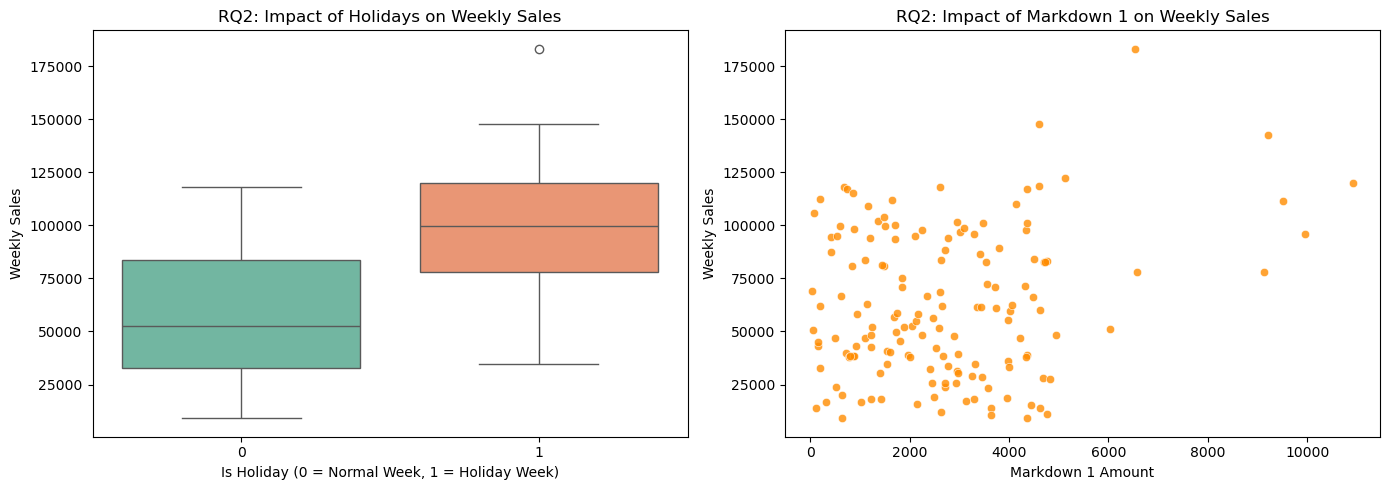

Average Sales during Normal Weeks: 57740.56
Average Sales during Holiday Weeks: 98067.76


In [5]:
# RQ2: Impact Analysis of Holidays and Markdowns on Weekly Sales
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 5))

# 1. Holiday Impact on Sales
plt.subplot(1, 2, 1)
sns.boxplot(x='is_holiday', y='weekly_sales', data=df_sample, palette='Set2')
plt.title('RQ2: Impact of Holidays on Weekly Sales')
plt.xlabel('Is Holiday (0 = Normal Week, 1 = Holiday Week)')
plt.ylabel('Weekly Sales')

# 2. Markdown 1 Impact on Sales (Scatter plot)
plt.subplot(1, 2, 2)
sns.scatterplot(x='markdown_1', y='weekly_sales', data=df_sample, color='darkorange', alpha=0.8)
plt.title('RQ2: Impact of Markdown 1 on Weekly Sales')
plt.xlabel('Markdown 1 Amount')
plt.ylabel('Weekly Sales')

plt.tight_layout()
plt.show()

# Calculating exact percentage change due to holidays
holiday_sales_mean = df_sample[df_sample['is_holiday'] == True]['weekly_sales'].mean()
normal_sales_mean = df_sample[df_sample['is_holiday'] == False]['weekly_sales'].mean()
print(f"Average Sales during Normal Weeks: {normal_sales_mean:.2f}")
print(f"Average Sales during Holiday Weeks: {holiday_sales_mean:.2f}")

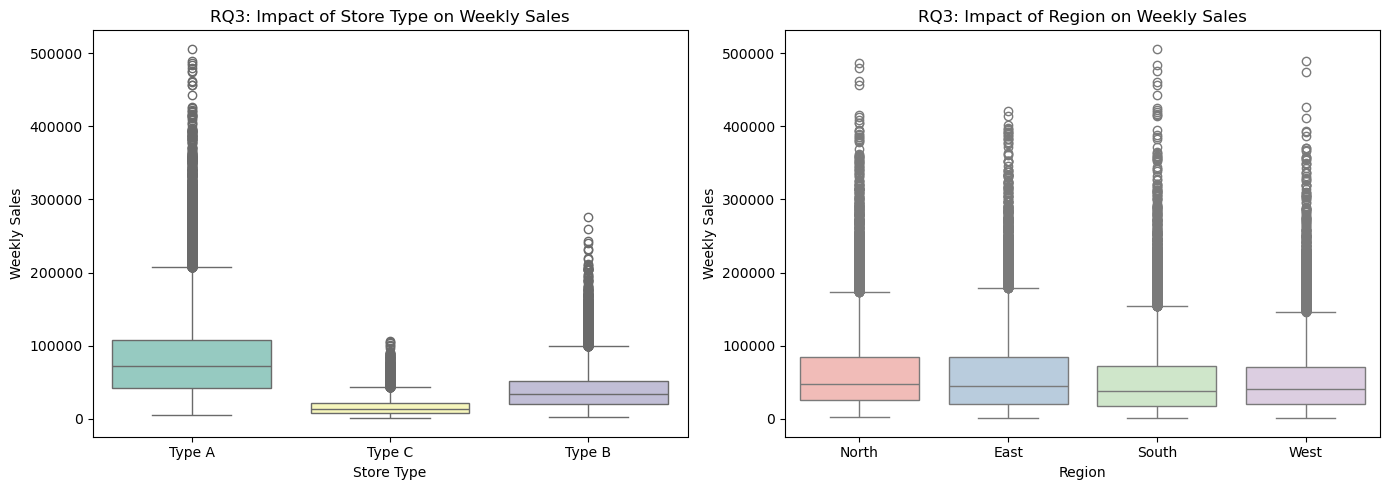

--- Sales Summary by Store Type ---


,mean,median,max
store_type_cat,,,
Type A,79952.039416,72152.070,505958.73
Type B,38289.061965,34109.715,276230.43
Type C,16184.417428,13512.975,106417.96


In [6]:
# RQ3: Impact of Store Types and Regions on Weekly Sales (Using Encoded Columns)
import matplotlib.pyplot as plt
import seaborn as sns

# Let's create a temporary categorical column for Store Type and Region for easy plotting
df_temp = master_df.copy()

# Determine Store Type
def get_store_type(row):
    if row['store_type_B'] == 1:
        return 'Type B'
    elif row['store_type_C'] == 1:
        return 'Type C'
    else:
        return 'Type A'  # Default baseline

df_temp['store_type_cat'] = df_temp.apply(get_store_type, axis=1)

# Determine Region
def get_region(row):
    if row['region_North'] == 1:
        return 'North'
    elif row['region_South'] == 1:
        return 'South'
    elif row['region_West'] == 1:
        return 'West'
    else:
        return 'East' # Default baseline

df_temp['region_cat'] = df_temp.apply(get_region, axis=1)

# Plotting RQ3
plt.figure(figsize=(14, 5))

# 1. Store Type vs Weekly Sales
plt.subplot(1, 2, 1)
sns.boxplot(x='store_type_cat', y='weekly_sales', data=df_temp, palette='Set3')
plt.title('RQ3: Impact of Store Type on Weekly Sales')
plt.xlabel('Store Type')
plt.ylabel('Weekly Sales')

# 2. Region vs Weekly Sales
plt.subplot(1, 2, 2)
sns.boxplot(x='region_cat', y='weekly_sales', data=df_temp, palette='Pastel1')
plt.title('RQ3: Impact of Region on Weekly Sales')
plt.xlabel('Region')
plt.ylabel('Weekly Sales')

plt.tight_layout()
plt.show()

# Summary statistics by Store Type Category
store_type_summary = df_temp.groupby('store_type_cat')['weekly_sales'].agg(['mean', 'median', 'max'])
print("--- Sales Summary by Store Type ---")
display(store_type_summary)

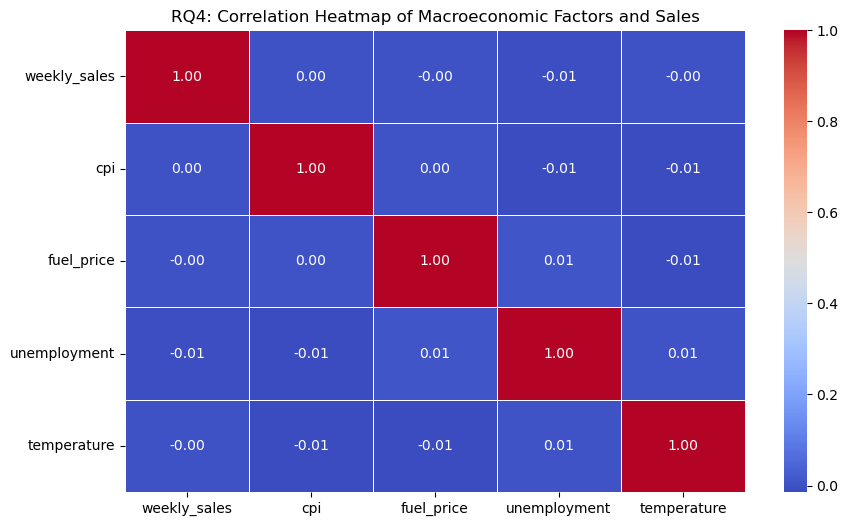

--- Correlation with Weekly Sales ---
weekly_sales    1.000000
cpi             0.000104
temperature    -0.000401
fuel_price     -0.001987
unemployment   -0.006969
Name: weekly_sales, dtype: float64


In [7]:
# RQ4: Impact of Macroeconomic Factors (CPI, Fuel Price, Unemployment, Temperature) on Weekly Sales
import matplotlib.pyplot as plt
import seaborn as sns

# Select macro columns and weekly sales for correlation analysis
macro_cols = ['weekly_sales', 'cpi', 'fuel_price', 'unemployment', 'temperature']
macro_corr = master_df[macro_cols].corr()

plt.figure(figsize=(10, 6))
sns.heatmap(macro_corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('RQ4: Correlation Heatmap of Macroeconomic Factors and Sales')
plt.show()

# Display correlation values with weekly_sales
print("--- Correlation with Weekly Sales ---")
print(macro_corr['weekly_sales'].sort_values(ascending=False))